# A-B Testing End to End (tea-tasting)

An **A/B test** (online controlled experiment) assigns users at random to a control arm and to one or more treatment
arms. Then it compares a metric between the arms. Random assignment makes the arms equal on average in everything
except the treatment. So a difference in the metric estimates the causal effect of the treatment.

This lesson analyzes a real randomized e-mail test from start to end. First it computes every number by hand with
SciPy and statsmodels. Then it repeats the analysis with **tea-tasting**, a Python package for experiment analysis,
and shows that the numbers are identical.

**After this lesson you can:**

1. Run the sanity checks before you look at results: sample sizes, sample ratio mismatch, covariate balance.
2. Compute the absolute and relative lift of a metric with a confidence interval by hand.
3. Run the same analysis with `tt.Experiment` and read its output.
4. Separate statistical significance from practical significance with a stated business threshold.
5. Analyze a test with three arms and correct the p-values for multiple comparisons.
6. Publish a results table and a forest plot of the lifts.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
**Services:** none.

In [1]:
import ast
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tea_tasting as tt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
pd.set_option("display.width", 130)
warnings.filterwarnings("ignore", category=FutureWarning)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
CONTROL, WOMENS, MENS = "No E-Mail", "Womens E-Mail", "Mens E-Mail"
METRICS = ["visit", "conversion", "spend"]       # all three are per customer (= per randomization unit)
print(df.shape)
print(df[["recency", "history", "segment", "visit", "conversion", "spend"]].head(3).to_string())

(64000, 12)
   recency  history        segment  visit  conversion  spend
0       10   142.44  Womens E-Mail      0           0    0.0
1        6   329.08      No E-Mail      0           0    0.0
2        7   180.65  Womens E-Mail      0           0    0.0


Each row is one customer. The **randomization unit** is the customer: the company assigned each customer to one of
three arms (`segment`). It sent the arm's e-mail and then recorded the next two weeks:

- `visit` is 1 if the customer visited the web site,
- `conversion` is 1 if the customer bought something,
- `spend` is the money spent in dollars.

The main question of this lesson: does the **Womens E-Mail** (treatment) increase these metrics compared with
**No E-Mail** (control)? Section 6 adds the Mens E-Mail arm.

## 1. Sanity Checks Before Any Result

Do the sanity checks first. If a check fails, the lifts are not trustworthy, so you do not need to look at them.

A **sample ratio mismatch** (SRM) occurs when the observed split of users differs from the planned split. The plan
here is 1/3 for each arm. A chi-square goodness-of-fit test compares the observed counts $n_k$ with the expected
counts $E_k = N/3$:

$$\chi^2 = \sum_{k} \frac{(n_k - E_k)^2}{E_k}, \qquad \text{df} = K - 1 .$$

A small p-value (most teams use $p < 0.001$ as the alarm level) means that assignment or logging has a bug.
Lesson 06 shows the typical causes of SRM.

In [2]:
counts = df["segment"].value_counts().reindex([CONTROL, WOMENS, MENS])
print(pd.DataFrame({"users": counts, "share_%": (100 * counts / counts.sum()).round(2)}).to_string())

chi3 = stats.chisquare(counts)                                   # H0: 1/3 : 1/3 : 1/3
chi2 = stats.chisquare(counts[[CONTROL, WOMENS]])                # H0: 1/2 : 1/2 (the pair we analyze)
print(f"SRM, 3 arms:            chi2 = {chi3.statistic:.3f}, df = 2, p = {chi3.pvalue:.3f}")
print(f"SRM, Womens vs control: chi2 = {chi2.statistic:.3f}, df = 1, p = {chi2.pvalue:.3f}")

               users  share_%
segment                      
No E-Mail      21306    33.29
Womens E-Mail  21387    33.42
Mens E-Mail    21307    33.29
SRM, 3 arms:            chi2 = 0.203, df = 2, p = 0.904
SRM, Womens vs control: chi2 = 0.154, df = 1, p = 0.695


The three arms hold 33.29 %, 33.42 % and 33.29 % of the customers. The SRM p-values are 0.904 (three arms) and
0.695 (the pair), so the split agrees with the plan.

Next, check **covariate balance**: the pre-treatment variables must have the same distribution in every arm. The
**standardized mean difference** (SMD) puts the difference of means on a common scale:

$$\text{SMD} = \frac{\bar x_T - \bar x_C}{\sqrt{(s_T^2 + s_C^2)/2}} .$$

A common rule accepts $|\text{SMD}| < 0.1$ as balance. The SMD does not depend on the sample size, so it does
not flag tiny differences in a large test (a t-test would).

In [3]:
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)

def smd(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    """Standardized mean difference of every column: (mean_a - mean_b) / pooled SD."""
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

balance = pd.DataFrame({arm: smd(X[df.segment == arm], X[df.segment == CONTROL]) for arm in [WOMENS, MENS]})
balance.insert(0, "control_mean", X[df.segment == CONTROL].mean())
print(balance.round(4).to_string())
print(f"largest |SMD|: {balance[[WOMENS, MENS]].abs().max().max():.4f} (rule: |SMD| < 0.1 is balanced)")

                      control_mean  Womens E-Mail  Mens E-Mail
recency                     5.7497         0.0052       0.0068
history                   240.8827         0.0065       0.0076
mens                        0.5532        -0.0086      -0.0046
womens                      0.5476         0.0049       0.0076
newbie                      0.5020         0.0026      -0.0009
zip_code_Rural              0.1473         0.0040       0.0137
zip_code_Surburban          0.4518        -0.0011      -0.0117
zip_code_Urban              0.4009        -0.0018       0.0020
channel_Multichannel        0.1223        -0.0053      -0.0042
channel_Phone               0.4378         0.0086      -0.0083
channel_Web                 0.4399        -0.0051       0.0110
largest |SMD|: 0.0137 (rule: |SMD| < 0.1 is balanced)


*Insight: The largest |SMD| over 11 covariates and two arms is 0.0137, far below 0.1. The randomization worked, so
the e-mail, and not a difference in customers, causes a difference in the outcome metrics.*

## 2. Metrics at the User Level

Compute every metric **per randomization unit**: one value per customer. Then the observations are independent and
the standard formulas for the variance of a mean are correct. Lesson 04 shows what goes wrong when the analysis
unit (for example a session) differs from the randomization unit.

In [4]:
ab = df[df.segment.isin([CONTROL, WOMENS])].copy()
by_arm = ab.groupby("segment")[METRICS].agg(["mean", "std"]).reindex([CONTROL, WOMENS])
print(by_arm.round(4).to_string())
spenders = ab[ab.spend > 0]
print(f"customers with spend > 0: {100 * len(spenders) / len(ab):.2f} % | spend among buyers: "
      f"median ${spenders.spend.median():.0f}, max ${spenders.spend.max():.0f} | "
      f"skewness of spend: {stats.skew(ab.spend):.1f}")

                visit         conversion           spend         
                 mean     std       mean     std    mean      std
segment                                                          
No E-Mail      0.1062  0.3081     0.0057  0.0755  0.6528  11.5882
Womens E-Mail  0.1514  0.3584     0.0088  0.0936  1.0772  15.1161
customers with spend > 0: 0.73 % | spend among buyers: median $90, max $499 | skewness of spend: 22.3


The visit rate rises from 10.62 % to 15.14 % and the conversion rate from 0.57 % to 0.88 %. Spend per customer
rises from $0.653 to $1.077. Only 0.73 % of the customers spent money, so spend is mostly zeros with a long right
tail (skewness 22.3). Its standard deviation ($11.59 in control) is 18 times its mean. Such a metric needs many
users: lesson 02 computes the sample size and lesson 05 reduces the variance with CUPED.

## 3. Lift and Confidence Interval by Hand

The **absolute lift** is $\Delta = \bar y_T - \bar y_C$. The arms are independent, so the variances add:

$$\widehat{\text{SE}}(\Delta) = \sqrt{\frac{s_T^2}{n_T} + \frac{s_C^2}{n_C}}, \qquad
\Delta \pm t_{0.975,\,\nu}\,\widehat{\text{SE}}(\Delta) .$$

This is the **Welch t-test**: it does not assume equal variances, and $\nu$ is the Welch-Satterthwaite degrees of
freedom. With 21,000 users per arm, $t_{0.975,\nu}$ is 1.96 for all practical purposes.

The **relative lift** is $\bar y_T / \bar y_C - 1$. It is a ratio of two random means, so its standard error comes
from the **delta method** (a first-order Taylor expansion, derived in lesson 04):

$$\operatorname{Var}\!\left(\frac{\bar y_T}{\bar y_C}\right) \approx \frac{1}{\bar y_C^2}\frac{s_T^2}{n_T}
+ \frac{\bar y_T^2}{\bar y_C^4}\frac{s_C^2}{n_C} .$$

A second version applies the delta method to $\log(\bar y_T/\bar y_C) = \log \bar y_T - \log \bar y_C$, with
$\operatorname{Var}(\log \bar y) \approx s^2 / (n \bar y^2)$. Its interval is
$\frac{\bar y_T}{\bar y_C}\, e^{\pm t \cdot \text{SE}_{\log}} - 1$. It is asymmetric and never goes below $-100\,\%$.
tea-tasting uses the log version.

In [5]:
def welch(var_t, n_t, var_c, n_c):
    """Standard error and Welch-Satterthwaite degrees of freedom for a difference of two means."""
    vt, vc = var_t / n_t, var_c / n_c
    return np.sqrt(vt + vc), (vt + vc) ** 2 / (vt ** 2 / (n_t - 1) + vc ** 2 / (n_c - 1))

def lift_by_hand(y_t: np.ndarray, y_c: np.ndarray, level: float = 0.95) -> dict:
    m_t, m_c, n_t, n_c = y_t.mean(), y_c.mean(), len(y_t), len(y_c)
    s2_t, s2_c = y_t.var(ddof=1), y_c.var(ddof=1)
    q = (1 + level) / 2
    # absolute lift: Welch t
    se, dof = welch(s2_t, n_t, s2_c, n_c)
    diff, half = m_t - m_c, stats.t.ppf(q, dof) * se
    # relative lift, delta method on the raw ratio (symmetric CI)
    se_rel = np.sqrt(s2_t / n_t / m_c ** 2 + m_t ** 2 * s2_c / n_c / m_c ** 4)
    # relative lift, delta method on log(m_t / m_c) (asymmetric CI, the tea-tasting default)
    se_log, dof_log = welch(s2_t / m_t ** 2, n_t, s2_c / m_c ** 2, n_c)
    k = np.exp(stats.t.ppf(q, dof_log) * se_log)
    return {"control": m_c, "treatment": m_t, "abs_lift": diff, "abs_lo": diff - half, "abs_hi": diff + half,
            "pvalue": 2 * stats.t.sf(abs(diff) / se, dof), "rel_lift": m_t / m_c - 1,
            "rel_lo_delta": m_t / m_c - 1 - stats.norm.ppf(q) * se_rel,
            "rel_hi_delta": m_t / m_c - 1 + stats.norm.ppf(q) * se_rel,
            "rel_lo": m_t / m_c / k - 1, "rel_hi": m_t / m_c * k - 1}

y = {arm: {m: ab.loc[ab.segment == arm, m].to_numpy(dtype=float) for m in METRICS} for arm in [CONTROL, WOMENS]}
manual = pd.DataFrame({m: lift_by_hand(y[WOMENS][m], y[CONTROL][m]) for m in METRICS}).T
print(manual.round(4).to_string())

            control  treatment  abs_lift  abs_lo  abs_hi  pvalue  rel_lift  rel_lo_delta  rel_hi_delta  rel_lo  rel_hi
visit        0.1062     0.1514    0.0452  0.0389  0.0516  0.0000    0.4261        0.3544        0.4977  0.3562  0.4995
conversion   0.0057     0.0088    0.0031  0.0015  0.0047  0.0002    0.5433        0.1932        0.8934  0.2301  0.9363
spend        0.6528     1.0772    0.4244  0.1690  0.6799  0.0011    0.6502        0.1491        1.1512  0.2180  1.2356


The next cell checks the hand formulas against two library functions. It uses the Welch test of SciPy and,
for the 0/1 conversion metric, the two-proportion z-test of statsmodels.

In [6]:
for m in METRICS:                                          # the same p-values and CIs from library calls
    t = stats.ttest_ind(y[WOMENS][m], y[CONTROL][m], equal_var=False)
    ci = t.confidence_interval(0.95)
    print(f"{m:10s} scipy Welch: p = {t.pvalue:.3e}, CI = [{ci.low:.5f}, {ci.high:.5f}]")

conv = ab.groupby("segment")["conversion"].agg(["sum", "count"]).reindex([WOMENS, CONTROL])
z, p_z = proportions_ztest(conv["sum"], conv["count"])
lo, hi = confint_proportions_2indep(*conv.loc[WOMENS], *conv.loc[CONTROL], method="wald")
print(f"conversion two-proportion z-test: z = {z:.3f}, p = {p_z:.3e}, Wald CI = [{lo:.5f}, {hi:.5f}]")

visit      scipy Welch: p = 2.432e-44, CI = [0.03889, 0.05157]
conversion scipy Welch: p = 1.560e-04, CI = [0.00150, 0.00472]
spend      scipy Welch: p = 1.129e-03, CI = [0.16896, 0.67987]
conversion two-proportion z-test: z = 3.780, p = 1.571e-04, Wald CI = [0.00150, 0.00472]


SciPy gives the same p-values and intervals as the hand formulas. For conversion, the two-proportion z-test gives
p = 1.571e-04 against 1.560e-04 for Welch. The two tests differ only in $n$ versus $n-1$ in the variance.

The two relative intervals differ most for the noisy metrics. For spend, the symmetric delta interval is
[14.9 %, 115.1 %] and the log interval is [21.8 %, 123.6 %]. The log interval is shifted to the right, because a
ratio of positive means has a right-skewed sampling distribution.

## 4. The Same Analysis with tea-tasting

tea-tasting describes an experiment as a set of metrics. `tt.Experiment` takes named metric objects and the name
of the variant column. `analyze()` computes each metric for one pair of variants:

| metric class | what it tests |
| :--- | :--- |
| `tt.SampleRatio()` | SRM check (binomial test, or normal approximation for large samples) |
| `tt.Mean("col")` | difference of means, Welch t-test by default; `covariate=` turns on CUPED |
| `tt.RatioOfMeans("num", "den")` | ratio metric with the delta method (lesson 04) |
| `tt.Proportion`, `tt.Quantile`, `tt.Bootstrap`, `tt.MannWhitneyU` | other tests for special cases |

The defaults come from `tt.get_config()`: $\alpha = 0.05$, two-sided, `equal_var=False`, `use_t=True`.

In [7]:
experiment = tt.Experiment(
    sample_ratio=tt.SampleRatio(),           # SRM check, normal approximation with continuity correction
    visit=tt.Mean("visit"),                  # Welch t-test by default (equal_var=False, use_t=True)
    conversion=tt.Mean("conversion"),
    spend=tt.Mean("spend"),
    variant="segment",
)
result = experiment.analyze(ab, control=CONTROL)
print(result)

metric       control treatment rel_effect_size rel_effect_size_ci   pvalue
sample_ratio   21306     21387               -             [-, -]    0.699
visit          0.106     0.151             43%         [36%, 50%] 2.43e-44
conversion   0.00573   0.00884             54%         [23%, 94%] 1.56e-04
spend          0.653      1.08             65%        [22%, 124%]  0.00113


In [8]:
tt_df = result.to_pandas().set_index("metric")
cols = {"effect_size": "abs_lift", "effect_size_ci_lower": "abs_lo", "effect_size_ci_upper": "abs_hi",
        "rel_effect_size_ci_lower": "rel_lo", "rel_effect_size_ci_upper": "rel_hi", "pvalue": "pvalue"}
gap = pd.DataFrame({c_tt: (tt_df.loc[METRICS, c_tt] - manual[c_m]).abs() for c_tt, c_m in cols.items()})
print("max |tea-tasting - by hand| per column:")
print(gap.max().map("{:.1e}".format).to_string())

n_c, n_t = counts[CONTROL], counts[WOMENS]                  # SRM: z-test with continuity correction, by hand
z_srm = (abs(n_t - (n_t + n_c) / 2) - 0.5) / np.sqrt((n_t + n_c) / 4)
print(f"SRM p by hand: {2 * stats.norm.sf(z_srm):.4f} | tea-tasting: {tt_df.loc['sample_ratio', 'pvalue']:.4f}")

max |tea-tasting - by hand| per column:
effect_size                 1.1e-16
effect_size_ci_lower        1.1e-16
effect_size_ci_upper        2.2e-16
rel_effect_size_ci_lower    2.2e-16
rel_effect_size_ci_upper    4.4e-16
pvalue                      2.0e-18
SRM p by hand: 0.6986 | tea-tasting: 0.6986


*Insight: tea-tasting and the hand calculation agree to 1e-16, the precision of a 64-bit float. A library is a
shortcut for formulas that you can check. The tea-tasting SRM p-value (0.699) uses a normal approximation with a
continuity correction. This is why it differs slightly from the chi-square value (0.695).*

## 5. Statistical vs Practical Significance

**Statistical significance** says that the effect is probably not zero. **Practical significance** says that the
effect is large enough to matter for the business. A test can show the first without the second.

Write the business threshold down **before** the test starts. This lesson uses two assumptions, not data from
Hillstrom. The gross margin is 30 % of spend, and each e-mail costs $0.075. Then the e-mail pays for
itself if it adds at least $0.075 / 0.30 = $0.25 of spend per customer.

In [9]:
MARGIN, COST = 0.30, 0.075                 # ASSUMPTIONS: 30 % gross margin, $0.075 per e-mail sent
BREAK_EVEN = COST / MARGIN                 # extra spend per customer that pays for the e-mail
s = manual.loc["spend"]
print(f"break-even lift: ${BREAK_EVEN:.3f} per customer")
print(f"observed lift:   ${s.abs_lift:.3f} per customer, 95 % CI [${s.abs_lo:.3f}, ${s.abs_hi:.3f}], p = {s.pvalue:.4f}")
print(f"statistically significant: {s.abs_lo > 0} | CI fully above break-even: {s.abs_lo > BREAK_EVEN}")
print(f"profit per 100,000 e-mails at the point estimate: ${100_000 * (MARGIN * s.abs_lift - COST):,.0f}; "
      f"at the CI lower bound: ${100_000 * (MARGIN * s.abs_lo - COST):,.0f}")

# one-sided test of H0: lift <= break-even (Welch)
se, dof = welch(y[WOMENS]["spend"].var(ddof=1), n_t, y[CONTROL]["spend"].var(ddof=1), n_c)
print(f"P(lift > break-even) test: t = {(s.abs_lift - BREAK_EVEN) / se:.2f}, "
      f"one-sided p = {stats.t.sf((s.abs_lift - BREAK_EVEN) / se, dof):.3f}")

break-even lift: $0.250 per customer
observed lift:   $0.424 per customer, 95 % CI [$0.169, $0.680], p = 0.0011
statistically significant: True | CI fully above break-even: False
profit per 100,000 e-mails at the point estimate: $5,232; at the CI lower bound: $-2,431
P(lift > break-even) test: t = 1.34, one-sided p = 0.090


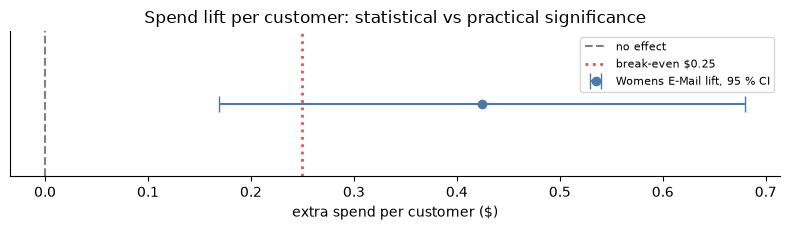

In [10]:
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.errorbar(s.abs_lift, 0, xerr=[[s.abs_lift - s.abs_lo], [s.abs_hi - s.abs_lift]], fmt="o", color="#4E79A7",
            capsize=6, label="Womens E-Mail lift, 95 % CI")
ax.axvline(0, color="grey", ls="--", label="no effect")
ax.axvline(BREAK_EVEN, color="#E15759", ls=":", lw=2, label=f"break-even ${BREAK_EVEN:.2f}")
ax.set(title="Spend lift per customer: statistical vs practical significance", xlabel="extra spend per customer ($)",
       yticks=[])
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

The spend lift is $0.424 per customer with p = 0.0011, so it is statistically significant. But the 95 % CI
[$0.169, $0.680] contains the break-even value of $0.25. A one-sided test of "lift > $0.25" gives p = 0.090. At
the point estimate, 100,000 e-mails earn $5,232; at the lower bound of the CI they lose $2,431.

| result | decision |
| :--- | :--- |
| CI above the threshold | ship |
| CI contains the threshold, point estimate above it | ship if the risk is acceptable, or run longer to narrow the CI |
| CI contains 0 and the threshold | no decision; the test has too little power |
| CI below the threshold | do not ship, even if p < 0.05 |

*Insight: "p < 0.05" answers "is there an effect?". The business asks "is the effect worth its cost?". Compare the
confidence interval with a threshold that you stated before the test.*

## 6. Three Arms and Multiple Comparisons

The test has two treatment arms and three metrics, so it asks 2 x 3 = 6 questions. If each question uses
$\alpha = 0.05$, the probability of at least one false positive, the **family-wise error rate** (FWER), is larger
than 5 %. For 6 independent tests it is $1 - 0.95^6 = 26.5\,\%$.

The **Holm** procedure controls the FWER at 5 % for any dependence between the tests:

1. Sort the $m$ p-values from smallest to largest: $p_{(1)} \le \dots \le p_{(m)}$.
2. Compare $p_{(i)}$ with $\alpha / (m - i + 1)$.
3. Stop at the first p-value that does not pass. Reject the null hypotheses of all p-values before it.

Holm rejects at least as many hypotheses as Bonferroni ($\alpha/m$ for all), so it is always the better choice.
In tea-tasting, `tt.adjust_fwer(..., method="bonferroni", arbitrary_dependence=True)` is Holm.

In [11]:
all_res = experiment.analyze(df, control=CONTROL, all_variants=True)    # every arm vs the control
adj = tt.adjust_fwer(all_res, metrics=METRICS, method="bonferroni", arbitrary_dependence=True)   # = Holm
rep = adj.to_pandas()
rep["arm"] = [ast.literal_eval(str(c))[1] for c in rep["comparison"]]   # "(control, treatment)" -> treatment
print(rep[["arm", "metric", "rel_effect_size", "pvalue", "pvalue_adj", "alpha_adj", "null_rejected"]]
      .to_string(index=False))

holm = multipletests(rep["pvalue"], method="holm")[1]                    # cross-check with statsmodels
print(f"max |tea-tasting Holm - statsmodels Holm| = {np.abs(holm - rep['pvalue_adj']).max():.1e}")

mw = experiment.analyze(df[df.segment != CONTROL], control=WOMENS)       # Mens vs Womens: a 7th question
print(mw.with_keys(("metric", "control", "treatment", "rel_effect_size", "rel_effect_size_ci", "pvalue")))

          arm     metric  rel_effect_size        pvalue    pvalue_adj  alpha_adj  null_rejected
  Mens E-Mail      visit         0.721405 1.364451e-112 8.186707e-112   0.008333              1
  Mens E-Mail conversion         1.188422  1.501816e-13  6.007263e-13   0.012500              1
  Mens E-Mail      spend         1.179289  1.163815e-07  3.491445e-07   0.016667              1
Womens E-Mail      visit         0.426055  2.432448e-44  1.216224e-43   0.010000              1
Womens E-Mail conversion         0.543313  1.560284e-04  3.120568e-04   0.025000              1
Womens E-Mail      spend         0.650152  1.129397e-03  1.129397e-03   0.050000              1
max |tea-tasting Holm - statsmodels Holm| = 0.0e+00
metric       control treatment rel_effect_size rel_effect_size_ci   pvalue
sample_ratio   21387     21307               -             [-, -]    0.702
visit          0.151     0.183             21%         [16%, 26%] 3.72e-18
conversion   0.00884    0.0125             42%     

The Holm correction rejects all six null hypotheses. The largest adjusted p-value is 0.0011
(Womens, spend). The correction matters for weaker effects: the Holm limit for the smallest p-value here is
0.05 / 6 = 0.0083 (`alpha_adj`).

The direct comparison Mens vs Womens is a seventh question. The Mens E-Mail has a 21 % higher visit rate and a
32 % higher spend per customer (95 % CI [2.7 %, 70 %], p = 0.0305). Bonferroni for 7 questions needs
p < 0.05 / 7 = 0.0071, so this spend result is weak evidence. Decide which comparisons are confirmatory before the test.

## 7. The Results Report

A team publishes the result as a **scorecard**. It has one row per arm and metric. Each row shows the control
value, the treatment value, the lifts with their CIs and the adjusted p-value. The sanity checks (SRM, balance) go at the top.

In [12]:
rep["order"] = rep["arm"].map({WOMENS: 0, MENS: 1}) * 10 + rep["metric"].map({m: i for i, m in enumerate(METRICS)})
rep = rep.sort_values("order").reset_index(drop=True)

def fmt(m, v):
    return f"${v:.3f}" if m == "spend" else f"{v:.2%}"

report = pd.DataFrame({
    "arm": rep.arm, "metric": rep.metric,
    "control": [fmt(m, v) for m, v in zip(rep.metric, rep.control)],
    "treatment": [fmt(m, v) for m, v in zip(rep.metric, rep.treatment)],
    "abs lift [95 % CI]": [f"{fmt(r.metric, r.effect_size)} [{fmt(r.metric, r.effect_size_ci_lower)}, "
                           f"{fmt(r.metric, r.effect_size_ci_upper)}]" for r in rep.itertuples()],
    "rel lift [95 % CI]": [f"{r.rel_effect_size:+.1%} [{r.rel_effect_size_ci_lower:+.1%}, "
                           f"{r.rel_effect_size_ci_upper:+.1%}]" for r in rep.itertuples()],
    "p (Holm)": rep.pvalue_adj.map("{:.2g}".format),
    "decision": np.where(rep.null_rejected == 1, "significant", "no evidence"),
})
print(report.to_string(index=False))

          arm     metric control treatment      abs lift [95 % CI]        rel lift [95 % CI] p (Holm)    decision
Womens E-Mail      visit  10.62%    15.14%    4.52% [3.89%, 5.16%]   +42.6% [+35.6%, +50.0%]  1.2e-43 significant
Womens E-Mail conversion   0.57%     0.88%    0.31% [0.15%, 0.47%]   +54.3% [+23.0%, +93.6%]  0.00031 significant
Womens E-Mail      spend  $0.653    $1.077 $0.424 [$0.169, $0.680]  +65.0% [+21.8%, +123.6%]   0.0011 significant
  Mens E-Mail      visit  10.62%    18.28%    7.66% [7.00%, 8.32%]   +72.1% [+64.0%, +80.6%] 8.2e-112 significant
  Mens E-Mail conversion   0.57%     1.25%    0.68% [0.50%, 0.86%] +118.8% [+76.8%, +170.9%]    6e-13 significant
  Mens E-Mail      spend  $0.653    $1.423 $0.770 [$0.485, $1.055] +117.9% [+62.8%, +191.6%]  3.5e-07 significant


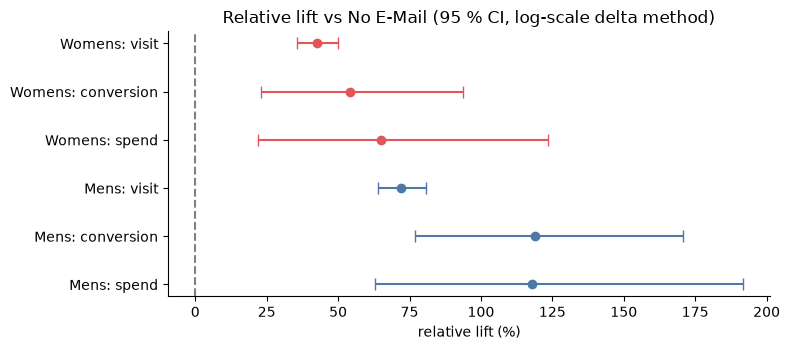

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = {WOMENS: "#E15759", MENS: "#4E79A7"}
for i, r in enumerate(rep.iloc[::-1].itertuples()):
    lo, mid, hi = 100 * r.rel_effect_size_ci_lower, 100 * r.rel_effect_size, 100 * r.rel_effect_size_ci_upper
    ax.errorbar(mid, i, xerr=[[mid - lo], [hi - mid]], fmt="o", color=colors[r.arm], capsize=4)
ax.set_yticks(range(len(rep)), (rep.arm.str.replace(" E-Mail", "") + ": " + rep.metric).iloc[::-1])
ax.axvline(0, color="grey", ls="--")
ax.set(title="Relative lift vs No E-Mail (95 % CI, log-scale delta method)", xlabel="relative lift (%)")
plt.tight_layout(); plt.show()

A **forest plot** shows each lift as a point and its CI as a horizontal line. The Mens E-Mail lifts are larger for
all three metrics. The CIs grow from visit to conversion to spend, because the metrics become rarer and noisier.
The CI of the Womens visit lift is 14 percentage points wide. The CI of the Womens spend lift is 102 points wide.

*Insight: The scorecard shows the sanity checks first and the uncertainty of every number. A reader can see at once
that both e-mails work and that the spend effect is uncertain.*

## 8. Common Mistakes

| mistake | what goes wrong | fix |
| :--- | :--- | :--- |
| **Peeking**: check the p-value every day and stop at the first p < 0.05 | the false positive rate grows far above 5 % | fix the sample size in advance (lesson 02) or use a sequential test (lesson 07) |
| change the primary metric after you see the data | you choose the metric that looks best: a hidden multiple comparison | write the primary metric and the threshold down before the test |
| **unit mismatch**: randomize users, analyze sessions or page views | rows of one user are correlated, so the SE is too small | aggregate per user or use the delta method (lesson 04) |
| ignore a failed SRM check | the arms differ in more than the treatment | stop, find the bug, rerun (lesson 06) |
| many metrics and arms without correction | some "wins" are false positives | Holm for confirmatory metrics; label the rest exploratory |
| report only the relative lift of a rare metric | +54 % sounds large; it is 0.31 percentage points | report the absolute and the relative lift |

## Real-World Use Case

Large experimentation platforms automate this workflow. Microsoft's experimentation platform (ExP) shows a
scorecard for every experiment. Kohavi, Tang and Xu describe it in *Trustworthy Online Controlled Experiments*
(2020): the SRM check comes first, and a failed SRM check hides the results.

Booking.com runs its experiments on
an in-house platform that any team can use. It publishes guidance on the same points: pre-registered metrics,
SRM checks and no early stopping. tea-tasting brings the same workflow to a notebook. It reads pandas and Polars data frames through Narwhals.
It also accepts pre-aggregated statistics per variant, so the warehouse can aggregate a large table first.